In [4]:
import os 
import cv2
import matplotlib

import numpy as np 
import pandas as pd 
import seaborn as sns 

import matplotlib.pyplot as plt
from matplotlib import gridspec


matplotlib.rcParams.update({
    'font.family': 'STIXGeneral',
    'mathtext.fontset': 'stix',
})

In [5]:
prefix = '/groups/karashchuk/karashchuklab/animal-datasets-processed/posetail-pretraining-v6'
animal_prefix = os.path.join(prefix, 'po-animal-sub256-motion', 'train')
human_prefix = os.path.join(prefix, 'point-odyssey-human', 'train')

outpath = '/home/ruppk2@hhmi.org/tracktail-paper/figures/v1'


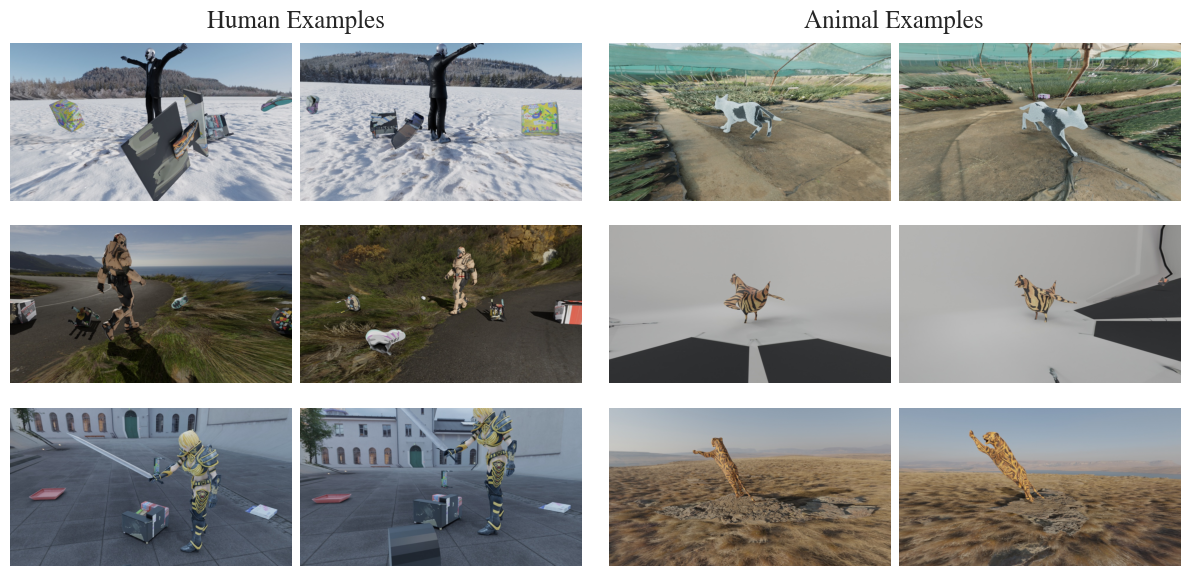

In [20]:

animal_examples = [

    {'trial': 'ani3', 
     'views': ['view3', 'view7'], 
     'frames': [376, 376]},

    {'trial': 'ani10', 
     'views': ['view0', 'view5'], 
     'frames': [199, 199]},

    {'trial': 'ani24', 
     'views': ['view2', 'view8'],
     'frames': [1202, 1202]},
]

human_examples = [
    # {'trial': 'hum10', 
    #  'views': ['view1', 'view2'],
    #  'frames': [10, 199]},
    {'trial': 'hum11', 
     'views': ['view1', 'view5'],
     'frames': [10, 10]},

    {'trial': 'hum39', 
     'views': ['view6', 'view5'],
     'frames': [189, 189]},

    {'trial': 'hum86', 
     'views': ['view0', 'view7'],
     'frames': [301, 301]},
]

# {'trial': 'hum111', 
#  'views': ['view2', 'view6'],
#  'frames': [70, 70]},

n_cams = 2
n_examples = 3

fs = 16
sns.set_style('ticks', {'font.family': 'STIXGeneral'})
fig = plt.figure(figsize=(13, 7))

gs = gridspec.GridSpec(1, 2, wspace=0.05, hspace=0.05, left=0.05, right=0.95)

gs_left  = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=gs[0], wspace=0.03, hspace=0.05)
gs_right = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=gs[1], wspace=0.03, hspace=0.05)

axes = []
for row in range(3):
    axes.append([
        fig.add_subplot(gs_left[row, 0]),
        fig.add_subplot(gs_left[row, 1]),
        fig.add_subplot(gs_right[row, 0]),
        fig.add_subplot(gs_right[row, 1]),
    ])

for row_idx, row_axes in enumerate(axes):
    for col_idx, ax in enumerate(row_axes):

        if col_idx < 2: 
            data_prefix = human_prefix
            examples = human_examples
        else: 
            data_prefix = animal_prefix 
            examples = animal_examples
        
        if col_idx % 2 == 0: 
            i = 0
        else: 
            i = 1

        trial = examples[row_idx]['trial']
        trial_num = ''.join(c for c in trial if c.isdigit())
        view = examples[row_idx]['views'][i]
        view_num = ''.join(c for c in view if c.isdigit())
        frame_num = examples[row_idx]['frames'][i] 
        img_str = f"img{str(frame_num).zfill(6)}.jpg"
        img_path = os.path.join(data_prefix, trial, 'trial', 'img', view, img_str)
        
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
        ax.imshow(img)
        ax.set_xticks([])
        ax.set_yticks([])
        # ax.axis('off')

        # ax.set_title(f"Frame {frame_num}, View {view_num}", fontsize = fs)
        # ax.set_title(f"View {view_num}", fontsize = fs)
        # if i == 0:
        #     ax.set_ylabel(f"Trial {trial_num}", fontsize = fs)


for row in axes:
    for ax in row:
        for spine in ax.spines.values():
            spine.set_visible(False)

fig.text(0.27, 0.89, "Human Examples", ha='center', fontsize=fs + 2, transform=fig.transFigure)
fig.text(0.73, 0.89, "Animal Examples", ha='center', fontsize=fs + 2, transform=fig.transFigure)

outdir = os.path.dirname(outpath)
if outdir:
    os.makedirs(outdir, exist_ok=True)
    
fig.savefig(os.path.join(outpath, 'po_examples.pdf'), dpi=800, bbox_inches = 'tight')